nov16_bags were recorded walking along a football field on pavement
need to calibrate K in the weinberg model. football field width in meters: 48.77

amber weinberg constant K=0.7
Lena weinberg constant K=0.81

Uses random forest model and non gravity subtracted data, as it performed the best in LOBO in world_frame_test.ipynb


Step Detection Test

**Goal:** Estimate the sensor's gravity vector from each bag's initial stillness period (adaptively detected), subtract it as a fixed offset, and use the resulting dynamic acceleration for step detection. This removes tilt dependence without needing per-sample YPR rotation.


In [2]:
import numpy as np
import joblib
from pathlib import Path
from mcap_ros2.reader import read_ros2_messages
from scipy.signal import butter, filtfilt, find_peaks
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

def read_bag(bag_path):
    ts, gyro, acc = [], [], []
    for msg in read_ros2_messages(str(bag_path)):
        if msg.channel.topic != '/imu':
            continue
        m = msg.ros_msg
        ts.append(m.header.stamp.sec + m.header.stamp.nanosec * 1e-9)
        gyro.append([m.imu.angular_velocity.x, m.imu.angular_velocity.y, m.imu.angular_velocity.z])
        acc.append([m.imu.linear_acceleration.x, m.imu.linear_acceleration.y, m.imu.linear_acceleration.z])

    ts = np.array(ts)
    t0 = ts[0]
    ts -= t0

    taps = []
    for msg in read_ros2_messages(str(bag_path)):
        if msg.channel.topic != '/tap':
            continue
        m = msg.ros_msg
        taps.append(m.stamp.sec + m.stamp.nanosec * 1e-9 - t0)

    return {
        'timestamps': ts,
        'linear_accelerations': np.array(acc),
        'angular_velocities': np.array(gyro),
        'tap_times': np.array(taps),
        'sample_rate': len(ts) / ts[-1] if ts[-1] > 0 else 40.0,
    }

from pathlib import Path

DATA_DIR = Path('nov16_bags')   # folder containing the bag folders

BAG_PATHS = sorted(
    (p.parent.name, p) for p in DATA_DIR.rglob('*.mcap')
)

bags = {}
for name, path in BAG_PATHS:
    b = read_bag(path)
    b['accel_mag'] = np.linalg.norm(b['linear_accelerations'], axis=1)
    b['gyro_mag'] = np.linalg.norm(b['angular_velocities'], axis=1)
    bags[name] = b
    print(f"{name:12s}  IMU={len(b['timestamps']):5d}  taps={len(b['tap_times']):3d}  duration={b['timestamps'][-1]:.1f}s")

rosbag2_2026_11_16-14_40_01  IMU= 3374  taps= 46  duration=84.3s
rosbag2_2026_11_16-14_42_14  IMU= 2755  taps= 45  duration=68.9s
rosbag2_2026_11_16-14_49_18  IMU= 1773  taps= 36  duration=44.3s
rosbag2_2026_11_16-14_50_49  IMU= 1816  taps= 36  duration=45.4s


## Adaptive Stillness Calibration → Gravity Estimate

Instead of assuming a fixed 1.5s stillness window, we **detect** how long each bag is actually still at the start by monitoring the rolling standard deviation of acceleration magnitude. When the person starts walking, the variance jumps sharply. We find that transition point and use 80% of the detected stillness window for gravity estimation — the 80% margin avoids contamination from the transition edge.

In [3]:
MAX_TAPS = 70
BUFFER = 2.0

taps = b['tap_times']

clean_taps = [taps[0]]
for t in taps[1:]:
    if t - clean_taps[-1] >= 0.3:
        clean_taps.append(t)
clean_taps = np.array(clean_taps)[:MAX_TAPS]

ts = b['timestamps']
mask = (ts >= clean_taps[0] - BUFFER) & (ts <= clean_taps[-1] + BUFFER)
new_t0 = ts[mask][0]

b['timestamps'] = ts[mask] - new_t0
b['linear_accelerations'] = b['linear_accelerations'][mask]
b['angular_velocities'] = b['angular_velocities'][mask]
b['tap_times'] = clean_taps - new_t0
b['accel_mag'] = np.linalg.norm(b['linear_accelerations'], axis=1)
b['gyro_mag'] = np.linalg.norm(b['angular_velocities'], axis=1)
b['sample_rate'] = len(b['timestamps']) / b['timestamps'][-1]



Keep only the first 70 taps from my_bag to reduce its dominance in training. 

In [4]:
MAX_TAPS = 70
BUFFER = 2.0

taps = b['tap_times']

clean_taps = [taps[0]]
for t in taps[1:]:
    if t - clean_taps[-1] >= 0.3:
        clean_taps.append(t)
clean_taps = np.array(clean_taps)[:MAX_TAPS]

ts = b['timestamps']
mask = (ts >= clean_taps[0] - BUFFER) & (ts <= clean_taps[-1] + BUFFER)
new_t0 = ts[mask][0]

b['timestamps'] = ts[mask] - new_t0
b['linear_accelerations'] = b['linear_accelerations'][mask]
b['angular_velocities'] = b['angular_velocities'][mask]
b['tap_times'] = clean_taps - new_t0
b['accel_mag'] = np.linalg.norm(b['linear_accelerations'], axis=1)
b['gyro_mag'] = np.linalg.norm(b['angular_velocities'], axis=1)
b['sample_rate'] = len(b['timestamps']) / b['timestamps'][-1]



In [5]:
def lowpass_filter(signal, cutoff=5.0, fs=40.0, order=4):
    b_coef, a_coef = butter(order, cutoff / (fs / 2.0), btype='low')
    return filtfilt(b_coef, a_coef, signal)

for name, b in bags.items():
    fs = b['sample_rate']
    b['accel_mag_filt'] = lowpass_filter(b['accel_mag'], fs=fs)
    b['gyro_mag_filt'] = lowpass_filter(b['gyro_mag'], fs=fs)

In [6]:
#mask out the sections that dont have walking using the peak detector



In [7]:

#classical detection
def detect_steps(signal_filt, fs, min_height_above_mean=0.5, min_distance_sec=0.35, min_prominence=0.3):
    min_height = signal_filt.mean() + min_height_above_mean
    min_distance = int(min_distance_sec * fs)
    return find_peaks(signal_filt, height=min_height, distance=min_distance, prominence=min_prominence)

for name, b in bags.items():
    peaks, props = detect_steps(b['accel_mag_filt'], b['sample_rate'])
    b['detected_peaks_body'] = peaks
    b['peak_props_body'] = props
    print(f"{name:12s} taps={len(b['tap_times']):3d}  candidate peaks={len(peaks):3d}")

rosbag2_2026_11_16-14_40_01 taps= 46  candidate peaks= 91
rosbag2_2026_11_16-14_42_14 taps= 45  candidate peaks= 90
rosbag2_2026_11_16-14_49_18 taps= 36  candidate peaks= 74
rosbag2_2026_11_16-14_50_49 taps= 36  candidate peaks= 74


## Peak Detection Comparison

Run the same peak detector on body-frame magnitude and gravity-subtracted dynamic magnitude. Compare precision/recall/F1.

In [8]:
def extract_features(peaks, accel_filt, gyro_filt, props, n, window_samples=10):
    features = []
    for i, pk in enumerate(peaks):
        lo = max(0, pk - window_samples)
        hi = min(n, pk + window_samples + 1)
        win_a = accel_filt[lo:hi]
        win_g = gyro_filt[lo:hi]

        a_std = max(win_a.std(), 1e-6)
        a_z = (win_a - win_a.mean()) / a_std
        skew = float(np.mean(a_z**3))
        kurt = float(np.mean(a_z**4)) - 3.0
        corr = float(np.corrcoef(win_a, win_g)[0, 1]) if len(win_a) > 1 else 0.0
        sharp = float(accel_filt[pk] - 0.5 * (accel_filt[max(0, pk-1)] + accel_filt[min(n-1, pk+1)]))

        features.append([
            accel_filt[pk], props['prominences'][i],
            win_a.mean(), win_a.std(), win_a.max() - win_a.min(),
            win_g.mean(), win_g.std(),
            accel_filt[pk] / win_a.mean() if abs(win_a.mean()) > 1e-6 else 1.0,
            skew, kurt, corr, sharp,
        ])
    return np.array(features) if features else np.empty((0, 12))

def label_peaks(peak_times, tap_times, tolerance_sec=0.3):
    labels = np.zeros(len(peak_times), dtype=int)
    used = set()
    for i, t in enumerate(peak_times):
        diffs = np.abs(tap_times - t)
        j = np.argmin(diffs)
        if diffs[j] <= tolerance_sec and j not in used:
            labels[i] = 1
            used.add(j)
    return labels

for name, b in bags.items():
    n = len(b['accel_mag_filt'])
    b['features_body'] = extract_features(b['detected_peaks_body'], b['accel_mag_filt'],
                                          b['gyro_mag_filt'], b['peak_props_body'], n)
    b['labels_body'] = label_peaks(b['timestamps'][b['detected_peaks_body']], b['tap_times'])
    print(f"{name:12s} {len(b['features_body'])} peaks ({b['labels_body'].sum()} labeled true)")

rosbag2_2026_11_16-14_40_01 91 peaks (46 labeled true)
rosbag2_2026_11_16-14_42_14 90 peaks (45 labeled true)
rosbag2_2026_11_16-14_49_18 74 peaks (36 labeled true)
rosbag2_2026_11_16-14_50_49 74 peaks (36 labeled true)


In [9]:
X = np.vstack([b['features_body'] for b in bags.values()])
y = np.concatenate([b['labels_body'] for b in bags.values()])

scaler = StandardScaler()
X_s = scaler.fit_transform(X)

clf = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
clf.fit(X_s, y)

from pathlib import Path
model_dir=Path('models')
model_dir.mkdir(parents=True, exist_ok=True)   #
model_path=model_dir/'step_rf_body.joblib'
joblib.dump({'model': clf, 'scaler': scaler}, model_path)
print(f"Trained on {len(X)} peaks ({int(y.sum())} pos) saved step_rf_body.joblib")

Trained on 329 peaks (163 pos) saved step_rf_body.joblib


In [10]:
# 1. Train once
X = np.vstack([b['features_body'] for b in bags.values()])
y = np.concatenate([b['labels_body'] for b in bags.values()])

scaler = StandardScaler()
X_s = scaler.fit_transform(X)

clf = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
clf.fit(X_s, y)

MAX_GAP_SEC = 1.5  # skip intervals across pauses

step_lengths = {}
for name, b in bags.items(): #bags is a dict of dicts
    y_pred = clf.predict(scaler.transform(b['features_body']))
    step_idx = b['detected_peaks_body'][y_pred == 1] 
    accel = b['accel_mag_filt']
    t = b['timestamps']

    lengths = []

    for i in range(00,len(step_idx)-1):
        low, high = step_idx[i], step_idx[i+1]

        segment=accel[low:high +1]
        swing = segment.max() - segment.min()
        lengths.append(0.81* swing ** 0.25) #weinberg formula, tune 1.1

    #amber bag K=0.7
    # rosbag2_2026_11_16-14_40_01 45 intervals, 
    # rosbag2_2026_11_16-14_42_14 44 intervals,

    #lena bag, K=0.81
    # rosbag2_2026_11_16-14_49_18 35 intervals, total = 48.13
    # rosbag2_2026_11_16-14_50_49 35 intervals, total = 47.96
    step_lengths[name] = np.array(lengths)
    print(f"{name:12s} {len(lengths)} intervals, total = {sum(lengths):.2f}")

rosbag2_2026_11_16-14_40_01 45 intervals, total = 56.24
rosbag2_2026_11_16-14_42_14 44 intervals, total = 56.58
rosbag2_2026_11_16-14_49_18 35 intervals, total = 48.73
rosbag2_2026_11_16-14_50_49 35 intervals, total = 48.56


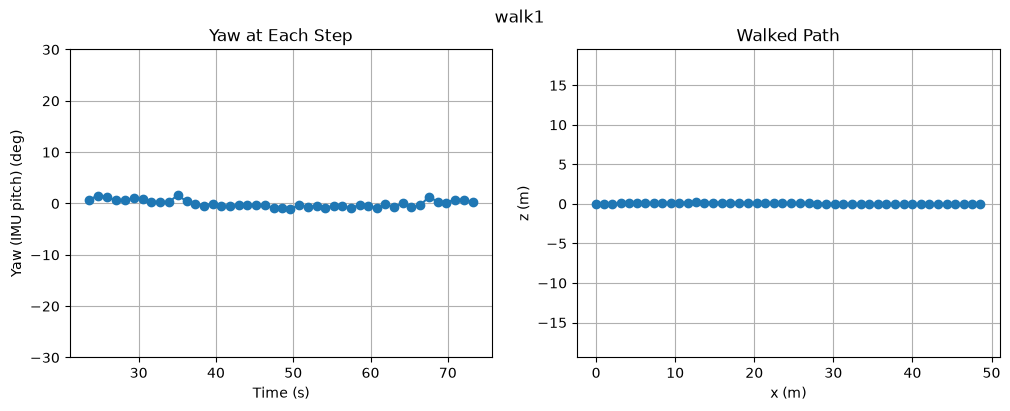

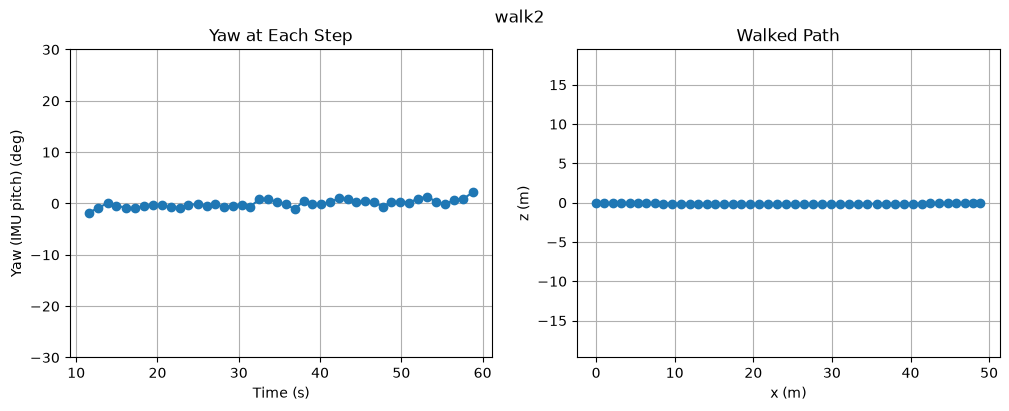

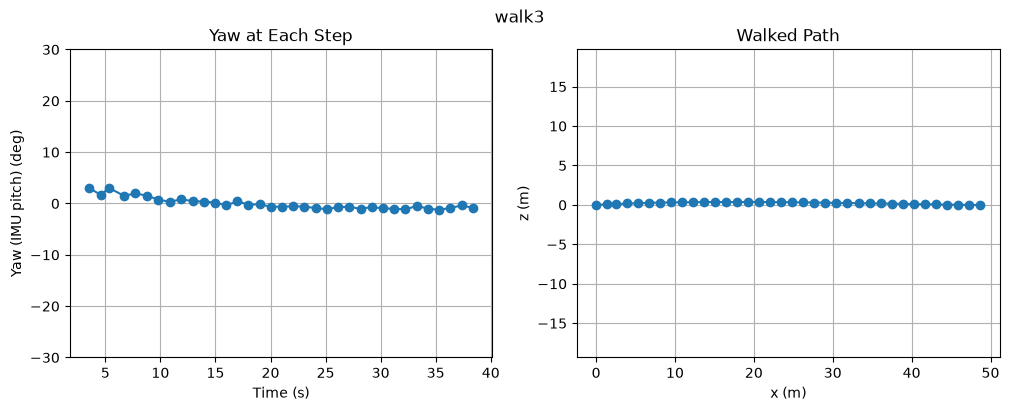

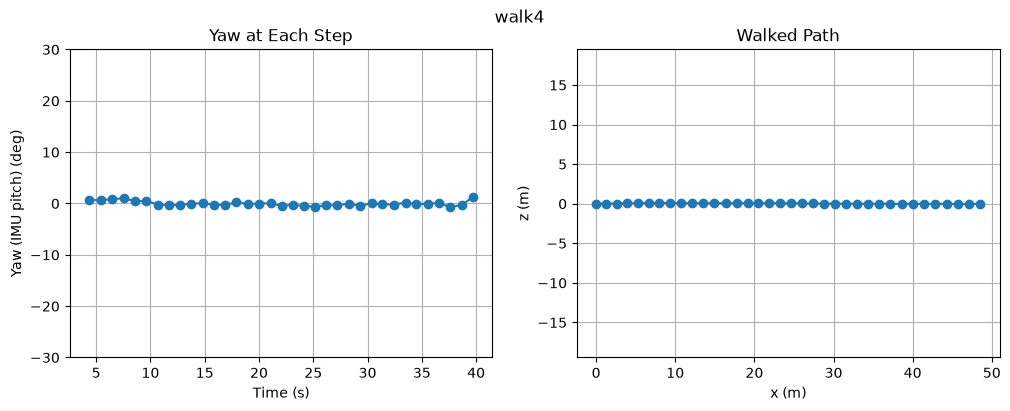

In [11]:
# Yaw and position plotting
%matplotlib inline

import matplotlib.pyplot as plt

# step model
saved = joblib.load('models/step_rf_body.joblib')
step_model = saved['model']
step_scaler = saved['scaler']

# Weinberg K for each walk
K = {
    'rosbag2_2026_11_16-14_40_01': 0.7,    # Amber
    'rosbag2_2026_11_16-14_42_14': 0.7,    # Amber
    'rosbag2_2026_11_16-14_49_18': 0.81,   # Lena
    'rosbag2_2026_11_16-14_50_49': 0.81,   # Lena
}

walk_number = 1
for name, path in BAG_PATHS:

    # 1. read time, IMU pitch, acceleration and gyro from the bag
    t, pitch, accel, gyro = [], [], [], []
    for msg in read_ros2_messages(str(path)):
        if msg.channel.topic != '/imu':
            continue
        m = msg.ros_msg
        t.append(m.header.stamp.sec + m.header.stamp.nanosec * 1e-9)
        pitch.append(float(m.raw.split(',')[2]))
        a = m.imu.linear_acceleration
        accel.append(np.sqrt(a.x**2 + a.y**2 + a.z**2))
        g = m.imu.angular_velocity
        gyro.append(np.sqrt(g.x**2 + g.y**2 + g.z**2))

    t = np.array(t)
    t = t - t[0]
    pitch = np.array(pitch)
    fs = len(t) / t[-1]

    # 2. find steps with the notebook's functions and model
    accel_filt = lowpass_filter(np.array(accel), fs=fs)
    gyro_filt = lowpass_filter(np.array(gyro), fs=fs)
    peaks, props = detect_steps(accel_filt, fs)
    features = extract_features(peaks, accel_filt, gyro_filt, props, len(accel_filt))
    steps = peaks[step_model.predict(step_scaler.transform(features)) == 1]

    # 3. one point per step: time, yaw (IMU pitch), Weinberg length
    step_times, step_yaws, step_lengths = [], [], []
    for i in range(len(steps) - 1):
        low = steps[i]
        high = steps[i + 1]
        step_times.append(t[low])
        step_yaws.append(pitch[low:high + 1].mean())
        swing = accel_filt[low:high + 1].max() - accel_filt[low:high + 1].min()
        step_lengths.append(K[name] * swing ** 0.25)

    step_yaws = np.array(step_yaws)
    step_yaws = step_yaws - step_yaws.mean()

    # 4. walk it out
    x = [0.0]
    z = [0.0]
    for i in range(len(step_lengths)):
        heading = np.radians(step_yaws[i])
        x.append(x[-1] + step_lengths[i] * np.cos(heading))
        z.append(z[-1] + step_lengths[i] * np.sin(heading))

    label = f"walk{walk_number}"

    # 5. a new figure for this walk: yaw on the left, path on the right
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle(label)

    ax1.plot(step_times, step_yaws, "o-")
    ax1.set_xlabel("Time (s)")
    ax1.set_ylabel("Yaw (IMU pitch) (deg)")
    ax1.set_title("Yaw at Each Step")
    ax1.set_ylim(-30, 30)
    ax1.grid(True)

    ax2.plot(x, z, "o-")
    ax2.set_xlabel("x (m)")
    ax2.set_ylabel("z (m)")
    ax2.set_title("Walked Path")
    ax2.axis("equal")
    ax2.grid(True)

    fig.savefig(label + ".png")
    plt.show()

    walk_number += 1